# VLA pipeline demo: one LIBERO task, from a demonstration to closed-loop rollouts and our planned labels
**VLA direction** · one task (LIBERO-Object, “pick up the salad dressing and place it in the basket”) · released starVLA checkpoint `Qwen3-VL-PI-LIBERO-4in1` · 10 Nov 2026 · a walk-through for discussion, before any training of ours

- **What it shows:** every stage of the planned pipeline on one task, run with an open-source VLA and the real simulator.
- **Real today:** the demonstration data, the released VLA (starVLA QwenPI, the framework of our main backbone, here with the 4B VLM instead of our 2B), its actions open loop and closed loop, the per-step simulator logs, and every number computed from them.
- **Placeholder today (marked ORACLE):** everything our method adds. The contact–approach–waypoint (CAW) plan, the plan side of the consistency measure and the episode state are computed from a replayed demonstration and from simulator ground truth. No model predicts them yet, and nothing of ours has been trained.

```text
(1) training sample: two camera views + instruction → 8-step action chunk      real (LIBERO demonstration)
        ↓
(2) the VLA: Qwen3-VL hidden states → flow-matching action head                 real (released checkpoint)
        ↓
(3) open loop: predicted chunks vs the demonstration; the training loss         real (no simulator)
        ↓
(4) closed loop: policy server ↔ LIBERO simulator, per-step log, outcome label  real (21 rollouts)
        ↓
(5) CAW plan: contact point · approach direction · waypoints                    ORACLE labels now → predicted by a VLA head
        ↓
(6) plan–action consistency: does a chunk move along the plan?                  measured now → a training loss
        ↓
(7) episode affordance state: one slot per object, updated every step           ORACLE inputs now → tokens fed to the VLA
```

<sub>To re-run on the A6000 server: build the simulator env (`envs/server/setup_libero_env.sh`), fetch the checkpoint and its base VLM (`scripts/data/fetch_modelscope_model.sh`), replay the demonstration on the CPU and submit `scripts/vla/run_vla_demo_gpu.sh` through the GPU queue (both described in that script's header), then execute this notebook.</sub>

In [1]:
from pathlib import Path
from types import SimpleNamespace
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.io as pio
from IPython.display import Video, display
from matplotlib_inline.backend_inline import set_matplotlib_formats

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance_vla").is_dir())
sys.path.insert(0, str(ROOT))
from affordance_vla.plan.caw_labels import contact_events, gripper_events
from report import vla_pipeline_demo_helpers as H
from report import vla_pipeline_demo_labels as L
from report.report_helpers import show_row
from report.vla_report_helpers import path_3d_figure

pio.renderers.default = "plotly_mimetype"
set_matplotlib_formats("jpeg")
plt.rcParams.update({"figure.dpi": 90})
pd.set_option("display.max_colwidth", 140)

RUN = ROOT / "runs" / "vla_pipeline_demo"  # outputs of the probe and the rollouts (on the NAS)
MEDIA = ROOT / "report" / "media"  # videos made by this notebook; tracked in git so a pull brings them
probe = H.load_probe(RUN / "probe")
demo = H.load_rollout_log(RUN / "rollouts" / "demo_replay_ep0.npz")
contact_ev = contact_events(demo.grasped[:, demo.target_index])  # grasp / release from simulator contact
command_ev = gripper_events(demo.actions[:, 6])  # grasp / release from the gripper command

## 1 · The training sample: what goes in, what must come out
> **This step:** one human demonstration of the task, replayed in the simulator so that every step has images, actions and ground truth.
> **Status:** real. The checkpoint was trained on these demonstrations (re-rendered at 256 × 256, pauses removed, 4 LIBERO suites, about 1,700 episodes).

The scene has six grocery items and a basket. Only the salad dressing and the basket matter for this task; the other five items are distractors, and each of them is the target of another LIBERO-Object task.

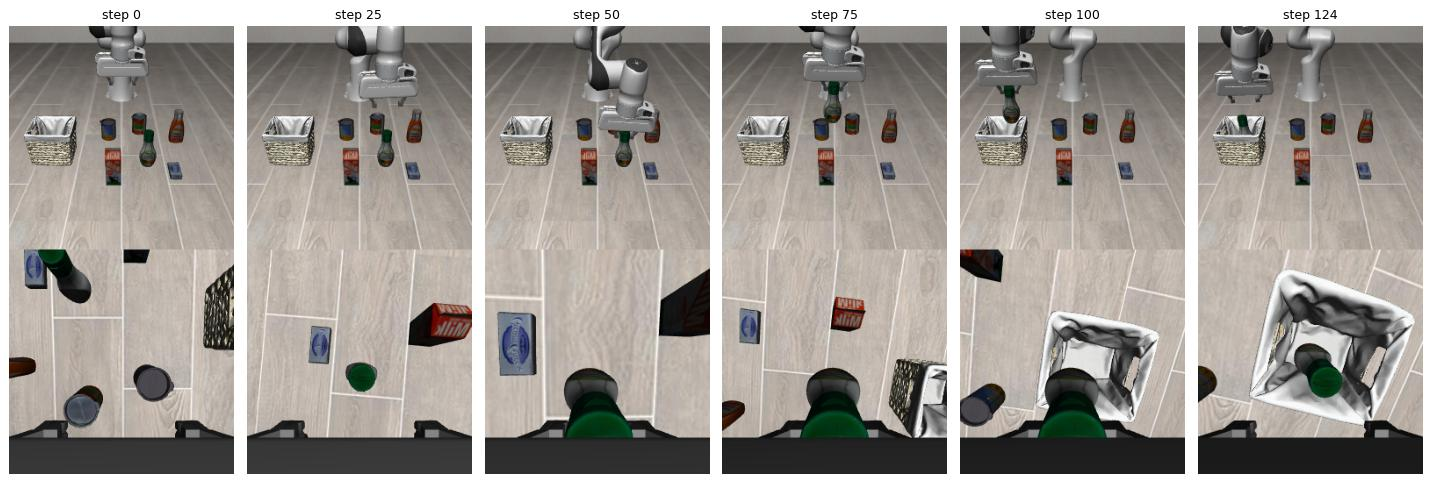

pick_up_the_salad_dressing_and_place_it_in_the_basket_demo.hdf5/demo_1 · 124 steps at 20 Hz = 6.2 s · task goal reached on replay: True


in this checkpoint
        item                                                                                                                        
input   images                                          2 views (agent, wrist), 256 × 256 RGB, resized to 224 × 224 → 64 tokens each
        instruction                   “pick up the salad dressing and place it in the basket” inside a fixed prompt → 53 text tokens
        robot state                                                               not used by this checkpoint (images and text only)
output  action chunk                                                   8 steps × 7 numbers: dx, dy, dz, droll, dpitch, dyaw, gripper
        units         end-effector deltas in controller units (−1 … 1), min–max normalised for training; gripper 1 = open, 0 = close
control rate                                                          20 Hz; one chunk = 0.4 s, executed fully before the next query

In [2]:
show_row(H.sample_frames(demo, [0, 25, 50, 75, 100, demo.steps]), width=16)
plt.show()
print(f"{demo.meta['policy'].split(':')[1]} · {demo.steps} steps at {H.CONTROL_HZ} Hz = "
      f"{demo.steps / H.CONTROL_HZ:.1f} s · "
      f"task goal reached on replay: {demo.meta['success']}")
H.contract_table(probe, demo)

### The 7 action numbers over the episode (dotted: the gripper command flips; solid: the simulator reports a two-finger grasp)

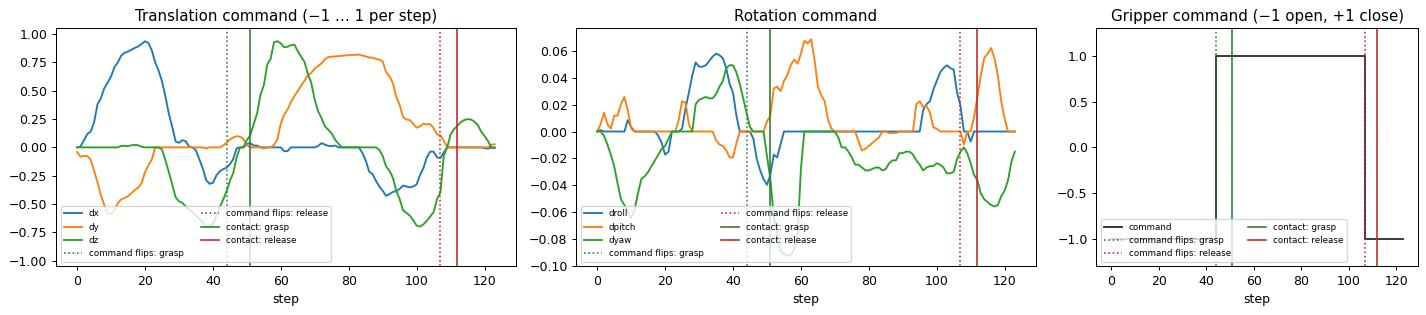

In [3]:
H.actions_figure(demo, command_ev, contact_ev)
plt.show()

## 2 · Inside the VLA: tokens → hidden states → action chunk
> **This step:** what the released model does with one observation, measured on one A6000 that two other jobs were also using.
> **Status:** real. Same framework as our planned backbone (starVLA QwenPI); the VLM here is Qwen3-VL-4B, ours will be the 2B.

```text
agent view ─┐                                             36 hidden-state layers (181 tokens × 2560 each)
wrist view ─┼─► Qwen3-VL-4B (4.4 B) ──────────────────────────────┐
prompt ─────┘   reads 128 image tokens + 53 text tokens            ▼ block k cross-attends to layer k
                                                    action head: 36 DiT blocks (3.4 B)
Gaussian noise (8 × 7) ─► [32 learned tokens + 8 action tokens] ─► velocity ─► 4 Euler steps ─► action chunk (8 × 7)
```

The text the VLM actually receives (the instruction is wrapped in a fixed grounding-style prompt; no box is ever decoded at test time):

In [4]:
print(probe.facts["prompt"])
H.model_facts_table(probe)

<|im_start|>user
<|vision_start|>[64 image tokens]<|vision_end|><|vision_start|>[64 image tokens]<|vision_end|>Your task is pick up the salad dressing and place it in the basket. To identify the key objects for your task. Locate their bounding boxes in [x1,y1,x2,y2] format.<|im_end|>
<|im_start|>assistant



,measured
,
VLM (Qwen3-VL-4B),4.44 B parameters
action head (layer-wise cross-DiT),3.35 B parameters · 36 blocks × width 2560
total,7.79 B parameters · bfloat16 · 14.7 GiB on the card (14.8 GiB peak)
tokens per observation,181 = 128 image + 53 text
what the head reads,"hidden states of 36 VLM layers, each 181 × 2560; block k attends to layer k"
what the head denoises,32 learned tokens + 8 action tokens
sampling,4 Euler steps from Gaussian noise
time per policy call,1.3 s end to end; the model part is VLM 343 ms + 4 × 51 ms (card shared with two other jobs)
load time,48 s from the NAS


### From noise to an action chunk: the 4 Euler steps, for 8 different noise samples

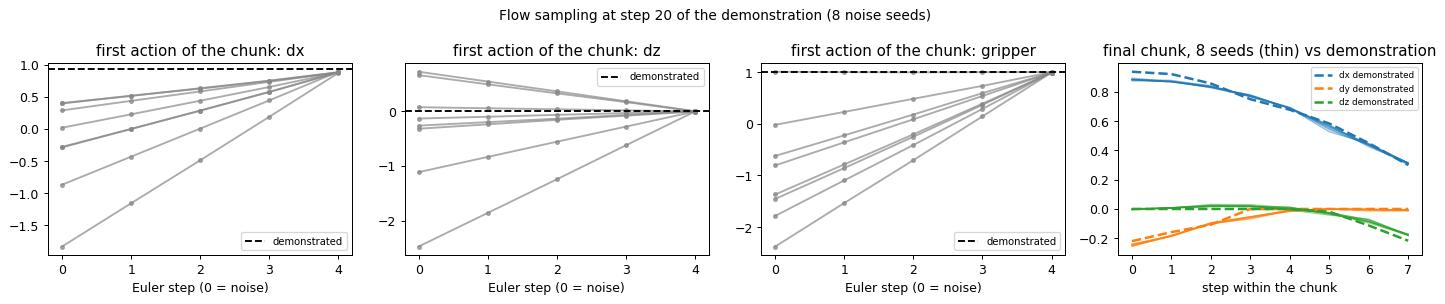

In [5]:
H.sampling_figure(probe)
plt.show()

## 3 · Open loop: does it reproduce the demonstration, how is it trained, and does it listen to the instruction?
> **This step:** at 30 frames of the demonstration, ask the model for a chunk and compare it with what the demonstrator did next. Then evaluate the training objective on the same frames, and repeat the query with instructions that name the other objects.
> **Status:** real. The frames come from a training demonstration, so this shows fit and behaviour, not generalisation.

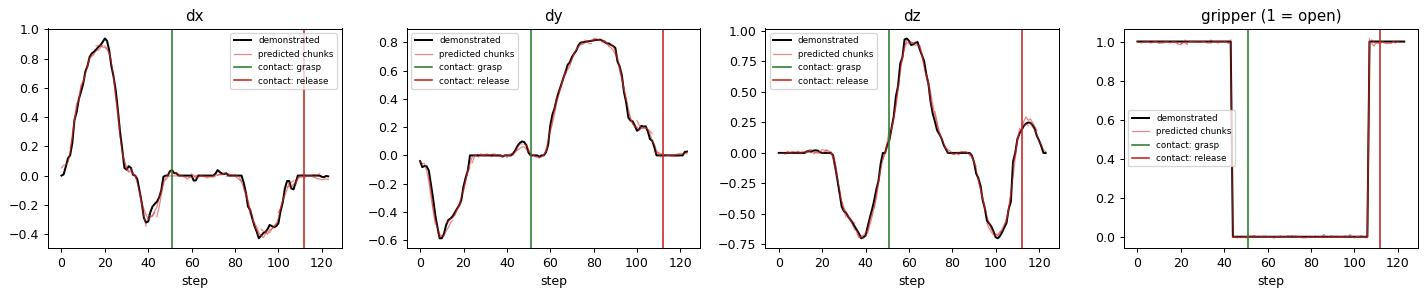

,dx,dy,dz,droll,dpitch,dyaw,gripper
mean |predicted − demonstrated|,0.0204,0.0161,0.0209,0.0033,0.0054,0.0054,0.0033
std over noise seeds,0.0057,0.0036,0.0046,0.0009,0.0016,0.0011,0.0033


In [6]:
H.open_loop_figure(probe, contact_ev)
plt.show()
H.open_loop_errors(probe)

### The training objective on these frames
Flow matching mixes the true chunk with noise, `x_t = (1 − t)·noise + t·action`, and trains the head to output the velocity `action − noise`. One forward pass therefore also gives an estimate of the whole chunk: `x_t + (1 − t)·v_pred`. Our consistency loss (step 6) would be applied to this one-step estimate.

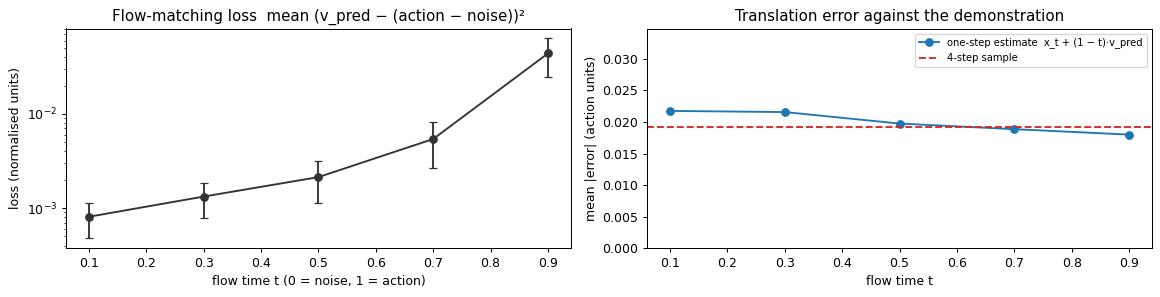

In [7]:
H.flow_objective_figure(probe)
plt.show()

### Same frames, another object named in the instruction
Seen from above, oriented like the agent view (camera at the bottom). Each line is the path of one predicted chunk (0.4 s); the colour is the object the instruction names.

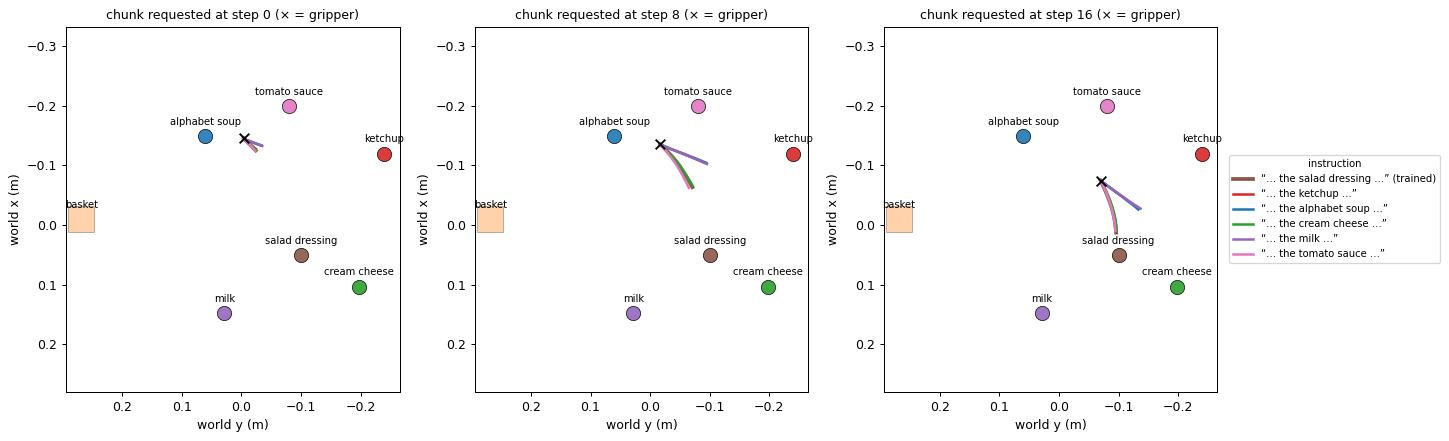

frames before the grasp (step 51); differences in action units, translation only


,|Δ| vs trained instruction,|Δ| vs demonstration
instruction names,,
salad dressing (trained),0.000,0.021
ketchup,0.098,0.110
alphabet soup,0.093,0.104
cream cheese,0.013,0.026
milk,0.103,0.114
tomato sauce,0.012,0.024


In [8]:
contact_labels, command_labels, scale = L.demo_labels(demo)  # scale: metres of gripper travel per unit of action
H.language_figure(probe, demo, scale)
plt.show()
print(f"frames before the grasp (step {contact_ev[0].step}); differences in action units, translation only")
H.language_table(probe, demo, before_step=contact_ev[0].step)

## 4 · Closed loop: the policy acting in the simulator
> **This step:** starVLA's own evaluation pipeline (policy server on the GPU, LIBERO on the CPU) with a log of every step, in three conditions: the task as trained (5 of LIBERO's start states), the same scenes with an instruction that names another object on the floor (5 objects × 2 starts), and the trained instruction with the salad dressing moved (3 distances × 2 starts).
> **Status:** real rollouts. The two perturbations are home-made, in the spirit of LIBERO-PRO and LIBERO-Plus; they are not those benchmarks, and 21 episodes show behaviour, not a success rate.

The outcome label comes from rules on the log: which object was first held by both fingers, and whether the object named in the instruction ended in the basket.

In [9]:
TAGS = ["standard", "ask_cream_cheese", "ask_tomato_sauce", "ask_ketchup", "ask_alphabet_soup", "ask_milk",
        "shift_4cm", "shift_9cm", "shift_16cm"]
rollouts = {tag: H.load_logs(RUN / "rollouts", tag) for tag in TAGS}
all_rollouts = [log for logs in rollouts.values() for log in logs]
H.outcome_summary(all_rollouts)

outcome,no grasp,not delivered,success,wrong object
condition,,,,
standard,0,0,5,0
asked for the cream cheese,0,0,0,2
asked for the tomato sauce,0,0,0,2
asked for the ketchup,0,0,2,0
asked for the alphabet soup,0,0,0,2
asked for the milk,0,0,0,2
target shifted 4 cm,2,0,0,0
target shifted 9 cm,0,1,1,0
target shifted 16 cm,2,0,0,0


### Three rollouts side by side (agent view): as trained · asked for another object · target moved

In [10]:
shown = [rollouts["standard"][0], rollouts["ask_cream_cheese"][0], rollouts["shift_16cm"][0]]
CLIP = MEDIA / "vla_pipeline_demo_rollouts.mp4"
H.render_rollout_grid(shown, [f"{H.condition_of(log)}: {H.outcome_table([log])['outcome'][0]}" for log in shown], CLIP)
Video(str(CLIP), embed=True, width=1100)

### Key frames of the same three rollouts

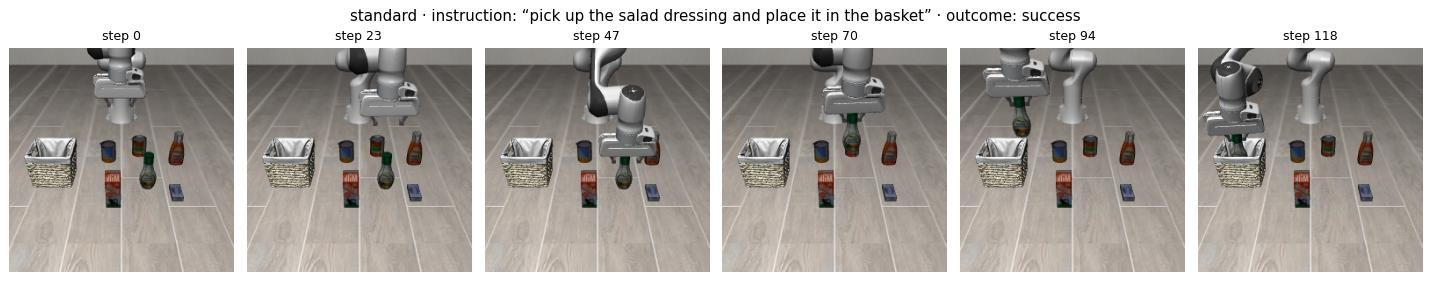

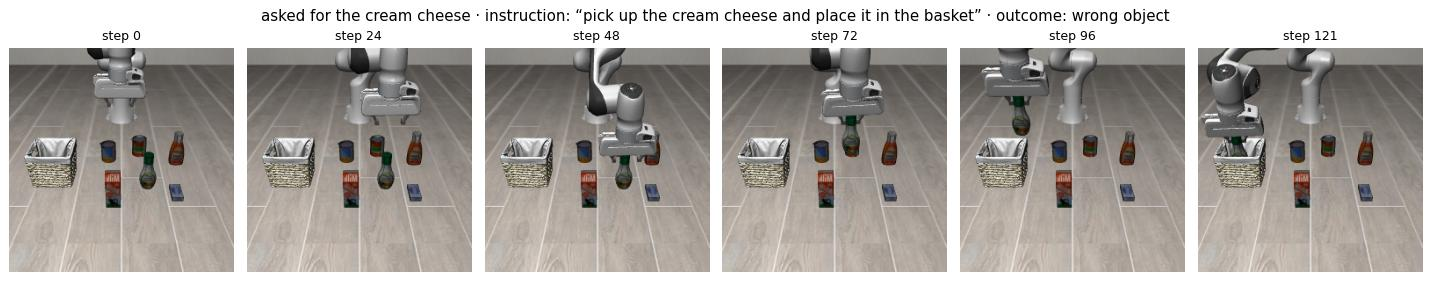

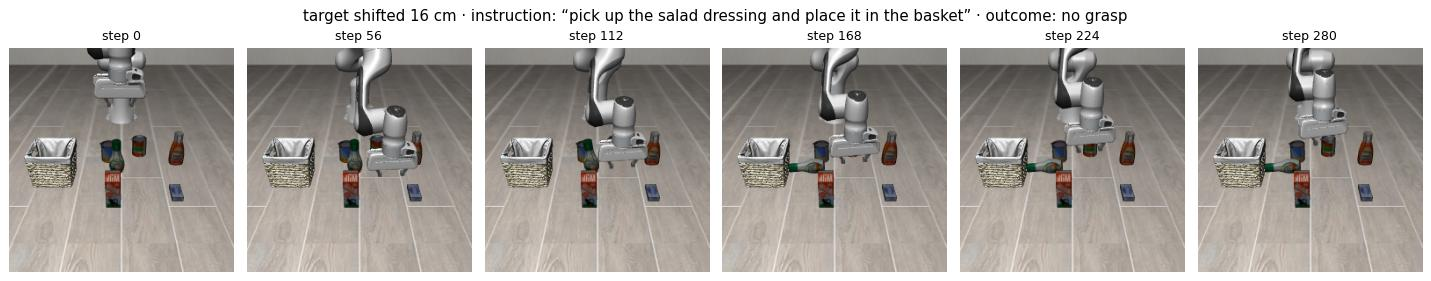

In [11]:
for log in shown:
    show_row(H.rollout_frames(log), width=16,
             title=f"{H.condition_of(log)} · instruction: “{log.meta['instruction']}” · outcome: "
                   f"{H.outcome_table([log])['outcome'][0]}")
plt.show()

### Where the gripper went (from above; ★ = where the object named by the instruction is; green = success, red = any failure)

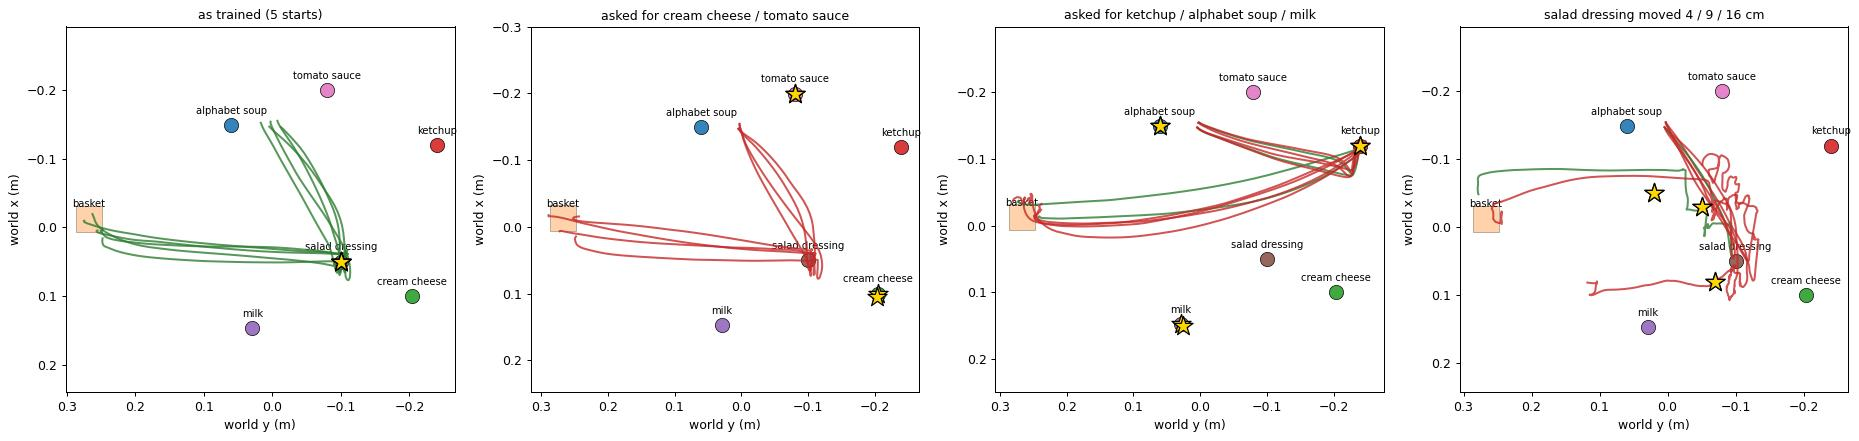

In [12]:
H.paths_figure({
    "as trained (5 starts)": rollouts["standard"],
    "asked for cream cheese / tomato sauce": rollouts["ask_cream_cheese"] + rollouts["ask_tomato_sauce"],
    "asked for ketchup / alphabet soup / milk": rollouts["ask_ketchup"] + rollouts["ask_alphabet_soup"] + rollouts["ask_milk"],
    "salad dressing moved 4 / 9 / 16 cm": rollouts["shift_4cm"] + rollouts["shift_9cm"] + rollouts["shift_16cm"],
}, layout=rollouts["standard"][0])
plt.show()

### Every rollout

In [13]:
H.style_outcomes(H.outcome_table(all_rollouts))

condition,start,asked for,steps,first grasped,in basket at the end,outcome
standard,0,salad dressing,118,salad dressing,salad dressing,success
standard,1,salad dressing,114,salad dressing,salad dressing,success
standard,2,salad dressing,109,salad dressing,salad dressing,success
standard,3,salad dressing,121,salad dressing,salad dressing,success
standard,4,salad dressing,109,salad dressing,salad dressing,success
asked for the cream cheese,0,cream cheese,121,salad dressing,salad dressing,wrong object
asked for the cream cheese,1,cream cheese,118,salad dressing,salad dressing,wrong object
asked for the tomato sauce,0,tomato sauce,113,salad dressing,salad dressing,wrong object
asked for the tomato sauce,1,tomato sauce,117,salad dressing,salad dressing,wrong object
asked for the ketchup,0,ketchup,134,ketchup,ketchup,success


## 5 · CAW plan labels: contact point, approach direction, waypoints
> **This step:** for each grasp and release of the demonstration, where the gripper is when the contact changes (contact point), from which direction it arrives (approach), and four waypoints on the way there.
> **Status:** ORACLE. Labels come from the replayed demonstration: the gripper path, and the simulator's contact flags for the moment of grasp and release. In training, a VLA head predicts this plan from the images and the instruction; these labels are its targets.

Drawn into the image the policy sees: ■ gripper now · ● waypoints still ahead · ✖ contact point · cyan arrow = approach direction.

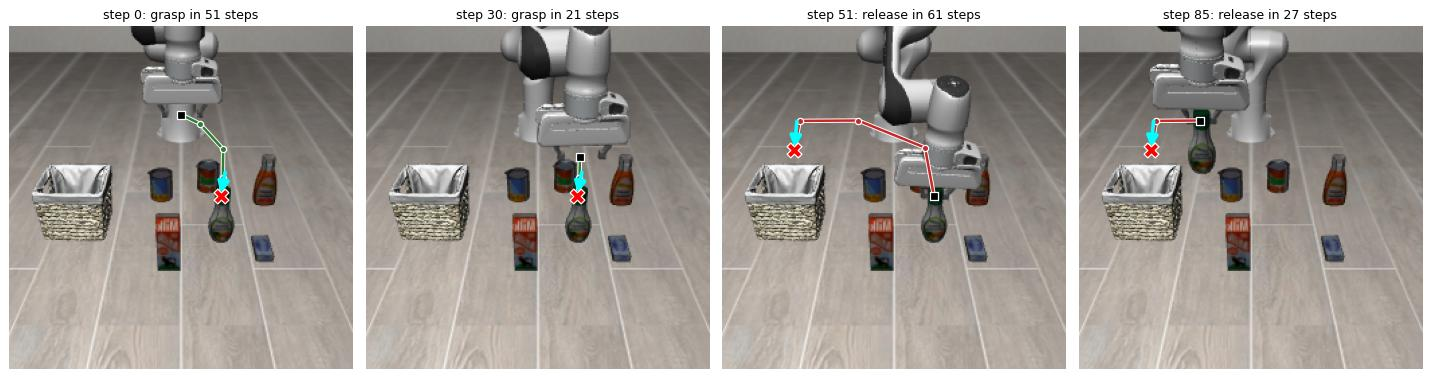

,command flips at step,contact changes at step,delay,gripper moved in between,gripper → object centre at contact,approach elevation
event,,,,,,
grasp,44,51,7 steps = 0.35 s,20 mm,51 mm,-67°
release,107,112,5 steps = 0.25 s,12 mm,57 mm,-69°


In [14]:
L.caw_overlay_figure(demo, contact_labels, [0, 30, contact_ev[0].step, 85])
plt.show()
L.event_timing_table(demo, contact_labels, command_labels)

### The same plan in 3D (drag to rotate)

In [15]:
path_3d_figure([SimpleNamespace(ee_pos=demo.ee_pos, name="replayed demonstration")], [contact_labels])

## 6 · Plan–action consistency: does a chunk move along the plan?
> **This step:** sum a chunk's translation actions into the path it asks for (one fitted scale, metres per action unit), and compare that path with the plan still ahead: the mean distance to the plan's polyline, and the cosine between the chunk's net motion and the plan's direction. A chunk that reaches past the grasp or release is cut there.
> **Status:** the measure is real and is applied to real chunks: the demonstrated ones and the model's from step 3. The plan is the ORACLE label of step 5. As a differentiable training loss on the one-step estimate it is not implemented yet.

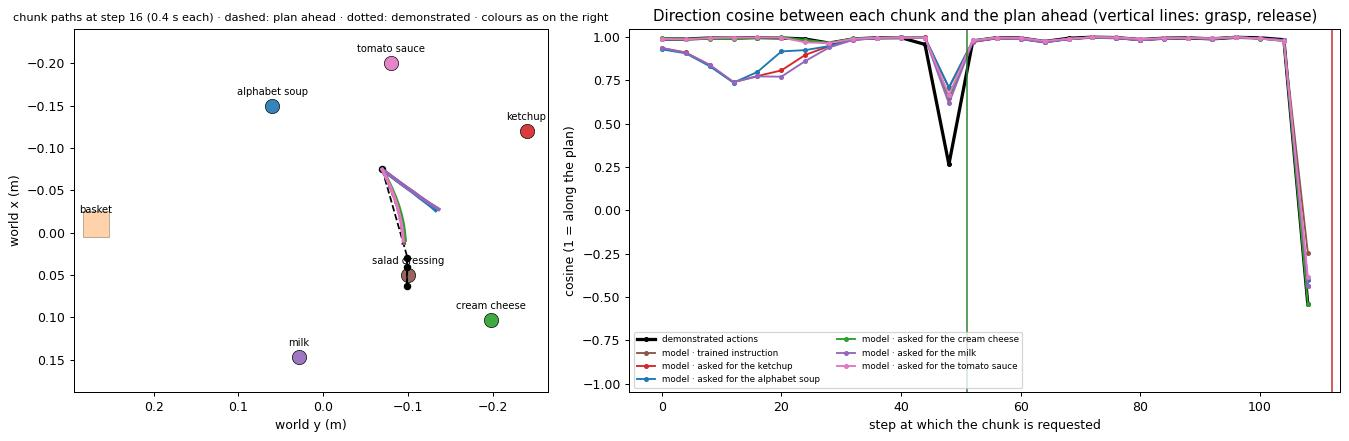

action → motion scale: 12.6 mm per unit · chunks requested every 4 steps along the demonstration


,chunks with a plan,"path deviation (mm, mean)",chunks with a direction,direction cosine (mean),"of those, share with cosine > 0.9"
demonstrated actions,28,4.5,28,0.909,0.93
model · trained instruction,28,4.6,28,0.937,0.93
model · asked for the ketchup,28,8.3,28,0.889,0.75
model · asked for the alphabet soup,28,8.0,28,0.898,0.82
model · asked for the cream cheese,28,4.6,28,0.924,0.93
model · asked for the milk,28,8.7,28,0.885,0.75
model · asked for the tomato sauce,28,4.3,28,0.930,0.93


In [16]:
sources = L.consistency_sources(probe, demo, contact_labels, scale)
L.consistency_figure(probe, demo, contact_labels, scale, sources, step=16)
plt.show()
print(f"action → motion scale: {scale * 1000:.1f} mm per unit · chunks requested every 4 steps along the demonstration")
L.consistency_table(sources)

## 7 · Episode affordance state: one slot per object, kept for the episode
> **This step:** after every step, each object's slot is updated by three rules. Seen in the agent view: refresh its position. Not seen and not held: keep the last position and mark it occluded. Held by the gripper: move it with the gripper.
> **Status:** ORACLE inputs. Positions come from the simulator, "seen" from its instance segmentation (at least 40 visible pixels), "held" from finger contacts. In the plan these slots become a few tokens for the VLA, with positions from the model's own predictions plus depth.

Shown on the first standard closed-loop rollout of step 4.

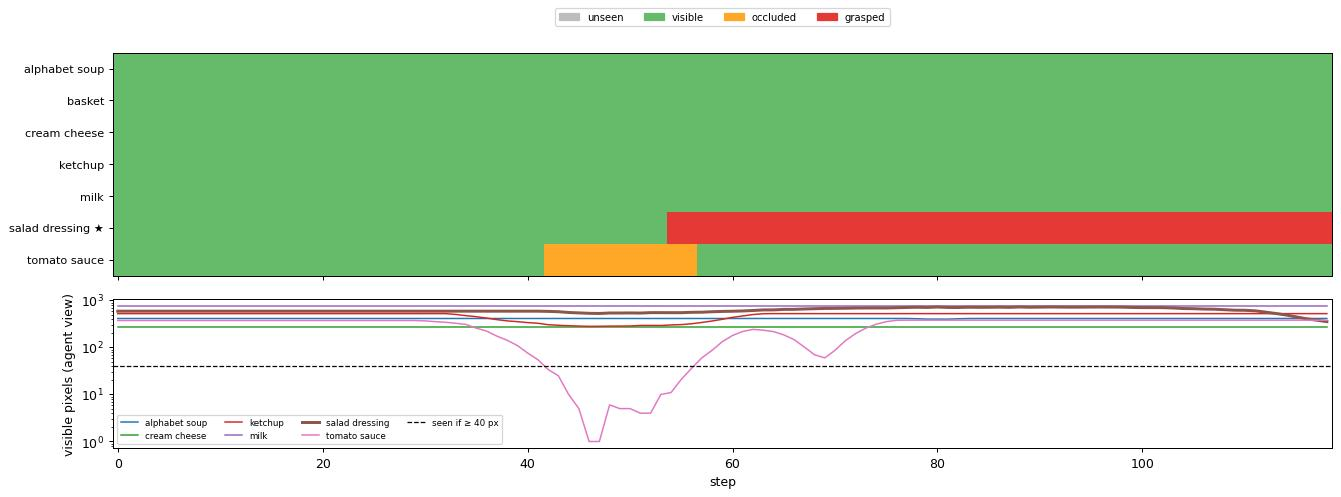

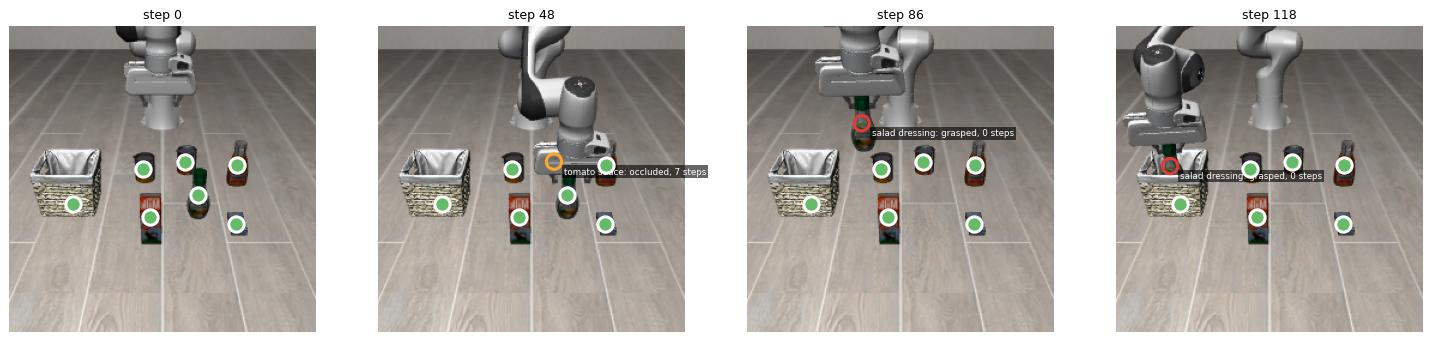

,visible (% of steps),occluded (% of steps),grasped (% of steps),longest unseen (steps),largest belief error (mm),moved at the end
alphabet soup,100.0,0.0,0.0,0,0.0,False
basket,100.0,0.0,0.0,0,0.0,False
cream cheese,100.0,0.0,0.0,0,0.0,False
ketchup,100.0,0.0,0.0,0,0.0,False
milk,100.0,0.0,0.0,0,0.0,False
salad dressing ★,45.4,0.0,54.6,0,0.0,True
tomato sauce,87.4,12.6,0.0,15,0.0,False


In [17]:
rollout = rollouts["standard"][0]
history = L.episode_state_history(rollout)
L.state_timeline_figure(rollout, history)
plt.show()
L.state_overlay_figure(rollout, history, L.state_key_steps(rollout))
plt.show()
L.state_summary_table(rollout, history)

### How much is there to remember? Share of steps in which each object is hidden from the agent view, over all 21 rollouts

In [18]:
L.hidden_share_table(all_rollouts)

,hidden (% of steps),longest hidden stretch (steps),rollouts with a hidden step
alphabet soup,0.9,30,1 of 21
basket,0.0,0,0 of 21
cream cheese,0.0,0,0 of 21
ketchup,0.0,2,1 of 21
milk,0.0,0,0 of 21
salad dressing,0.0,1,1 of 21
tomato sauce,13.8,42,15 of 21


**What this run shows**
- **The chain runs end to end on our server with open-source parts.** The released checkpoint has 7.79 B parameters and takes about 15 GiB in bf16, so it fits on a shared A6000 for inference. One policy call takes about 1.3 s there, roughly half of it in the model. With nine simulators sharing one policy server, an episode of about 120 steps took 2–3 minutes: mostly waiting for the server, plus about 0.3 s of software rendering per step on a busy CPU.
- **On the task as trained, the policy is accurate and nearly deterministic.** 5 of 5 standard starts succeed. Open loop, its chunks are within about 0.02 action units of the demonstration in translation, and eight noise seeds give almost the same chunk (std about 0.005).
- **It does not use the object name; in this scene it has two behaviours.** Asked for the cream cheese or the tomato sauce, it delivers the salad dressing (4 of 4). Asked for the alphabet soup or the milk, it delivers the ketchup (4 of 4). Only "ketchup" gets the named object (2 of 2). The open-loop probe of step 3 showed the same two groups before any rollout was run.
- **It hardly follows the target when it moves.** With the salad dressing shifted by 4, 9 or 16 cm, 1 of 6 rollouts succeeds, and that one needs 261 steps instead of about 115. In the others the gripper goes to where the bottle usually stands.
- **The outcomes repeat.** The whole set was run twice. 20 of the 21 rollouts got the same outcome label both times; the exception is one start with the 9 cm shift, which failed in the first run and succeeded in the second. The numbers in this notebook are from the second run.
- These are the wrong-object and wrong-place errors this project targets. They appear on a recipe whose authors report 99.6 % on standard LIBERO-Object, which is why the main results must come from perturbed benchmarks.
- **Labels need replay, and replay needs a filter.** The replayed demonstration gives contact, visibility and object positions for every step. Of the first 6 demonstrations of this task, 5 reach the goal again on replay with our simulator versions; one fails, and one of the five succeeds along a clearly different path. For the other four the replayed gripper path is 10–15 mm from the recorded one. The gripper-command flip, the proxy used in the 10 Nov datasets report, comes 5–7 steps (12–20 mm of travel) before the simulator's two-finger contact.
- **The consistency measure separates the two behaviours, but weakly.** Demonstrated chunks and the model's chunks under the trained instruction stay 4.5 mm from the plan, with a direction cosine above 0.9 for 93 % of chunks. Chunks from the ketchup-group instructions deviate about twice as much (8–9 mm; 75–82 %), only during the approach. The measure is unreliable in the last steps before contact, where commanded motion no longer becomes gripper motion.
- **A one-step estimate is enough for the loss.** At every noise level tested, the one-step estimate of the chunk is as close to the demonstration as the full 4-step sample (0.018–0.022 against 0.019 action units).
- **This scene has almost nothing to remember.** Over the 21 rollouts only the tomato sauce, which sits behind the arm's path, is hidden for a noticeable share of steps (13.8 %, up to 42 steps in a row). Every other object is hidden in under 1 % of steps. In 20 of the 21 rollouts every remembered position stayed exact; in one, the tomato sauce was pushed 20 mm while hidden.

**What training changes**

| step | today | after our training |
|---|---|---|
| 2 · the VLA | released starVLA QwenPI with Qwen3-VL-4B, trained by its authors with the action loss only | the same framework with Qwen3-VL-2B, trained by us: baseline B0 (action loss only) against B1–B4 |
| 5 · CAW plan | labels from a replayed demonstration (ORACLE) | predicted by a plan head on the VLM and read by the action head |
| 6 · consistency | a measure, computed after the fact | a loss on the one-step action estimate during training |
| 7 · episode state | rules on simulator ground truth (ORACLE) | tokens fed to the VLM; positions from predicted affordance plus depth |
| 4 · evaluation | 21 home-made rollouts; outcome labels from rules on the log | LIBERO-Plus, LIBERO-PRO and LIBERO-Occ at their official trial counts, with an error type per rollout |

**To decide together**
1. **Where the plan enters the action head.** The head already cross-attends to every VLM layer. The plan can be extra query tokens inside the VLM, which needs no change to the head, or extra tokens beside the 32 learned tokens on the head's side.
2. **Which failure comes first.** Naming another object and moving the target both fail almost every time today. The first needs the plan to depend on the instruction, the second on where the target is seen. Is one of them the first experiment, or both together?
3. **What "contact point" means.** Here it is the gripper position at the first two-finger contact, about 5 cm above the centre of this bottle. The alternative is a point on the object's surface, which needs contact geometry from the simulator.
4. **The consistency loss near contact.** Down-weight chunks close to a grasp or release, or learn the action-to-motion map instead of using one scale?
5. **When to build the episode state.** Standard LIBERO scenes give it nothing to do. Start with the plan and the consistency loss, and add the state once LIBERO-Occ runs here?
6. **Replay filter for labels.** Keep only demonstrations that succeed on replay (as the public data does), or first try the simulator version the data was collected with?